**CAPSTONE MODUL 3 : BIKE SHARING - IVAN SETYA ANANDA**

****
# **Business Understanding**
****

**Context:**
***
Bike-sharing systems represent a modern evolution of traditional bike rentals, automating the entire process from membership to rental and return. Users can effortlessly rent a bike from one station and return it to another
Focusing on the casual user segment—tourists, occasional riders, and non-regular commuters—offers substantial growth opportunities. Casual users typically seek flexibility and convenience, making them a lucrative market. The rich data generated by bike-sharing systems, including travel duration and station usage, provides valuable insights into urban mobility patterns. This data can be leveraged to enhance user experience, optimize operations, and drive targeted marketing strategies.


**Stakelhoders:**
***
Marketing Team ( Capital Bikeshare company)
 -  **Role:** Develop and suggest marketing campaigns to attract casual users.
 -  **Involvement:** Advertising, promotions, partnerships.


**Problem Statement:**
***
Despite a steady influx of casual users, our bike rental business has not fully capitalized on this market segment. We aim to identify the key factors influencing casual users' decision-making processes and develop targeted marketing and operational strategies to enhance their rental experience.


**Business Objective:**
***
Marketing Team Capital Bikeshare Company wants to know:
1.	Which Key Features are significant in predicting the casual shared bike demand
2.	How well those features describe the shared bike demand


***

In [75]:
# import the dataset
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Lasso
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor
from xgboost.sklearn import XGBRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import Pipeline

from feature_engine.selection import DropFeatures
from feature_engine.wrappers import SklearnTransformerWrapper
from feature_engine.transformation import (
LogTransformer,
LogCpTransformer,
YeoJohnsonTransformer
)

import warnings
warnings.filterwarnings('ignore')

In [76]:
bike = pd.read_csv('data_bike_sharing.csv')
bike

,dteday,hum,weathersit,holiday,season,atemp,temp,hr,casual,registered,cnt
0,2011-12-09,0.62,1,0,4,0.3485,0.36,16,24,226,250
1,2012-06-17,0.64,1,0,2,0.5152,0.54,4,2,16,18
2,2011-06-15,0.53,1,0,2,0.6212,0.62,23,17,90,107
3,2012-03-31,0.87,2,0,2,0.3485,0.36,8,19,126,145
4,2012-07-31,0.55,1,0,3,0.6970,0.76,18,99,758,857
...,...,...,...,...,...,...,...,...,...,...,...
12160,2012-01-25,0.75,1,0,1,0.2273,0.24,7,14,243,257
12161,2012-07-06,0.62,1,0,3,0.7424,0.78,0,39,63,102
12162,2012-02-20,0.60,2,1,1,0.2121,0.24,5,0,6,6
12163,2012-03-31,0.77,2,0,2,0.4242,0.42,2,14,55,69


***
# **Data Collection and Preprocessing**
***

## **Collect Data**

In [77]:
bike.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12165 entries, 0 to 12164
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   dteday      12165 non-null  object 
 1   hum         12165 non-null  float64
 2   weathersit  12165 non-null  int64  
 3   holiday     12165 non-null  int64  
 4   season      12165 non-null  int64  
 5   atemp       12165 non-null  float64
 6   temp        12165 non-null  float64
 7   hr          12165 non-null  int64  
 8   casual      12165 non-null  int64  
 9   registered  12165 non-null  int64  
 10  cnt         12165 non-null  int64  
dtypes: float64(3), int64(7), object(1)
memory usage: 1.0+ MB


There is data type error for `dteday` column; it should be `DateTime`, because of data time stamp type

There are data types error for `weathersit, holiday, season, hr` columns; it should be `Category`, because

## **Clean Data**

In [78]:
# percentage of missing values
missing_columns = (bike.isnull().sum())*100/len(bike)
missing_rows = (bike.isnull().sum(axis=1))*100/len(bike)
display(missing_columns,missing_rows)

dteday        0.0
hum           0.0
weathersit    0.0
holiday       0.0
season        0.0
atemp         0.0
temp          0.0
hr            0.0
casual        0.0
registered    0.0
cnt           0.0
dtype: float64

0        0.0
1        0.0
2        0.0
3        0.0
4        0.0
        ... 
12160    0.0
12161    0.0
12162    0.0
12163    0.0
12164    0.0
Length: 12165, dtype: float64

<Axes: >

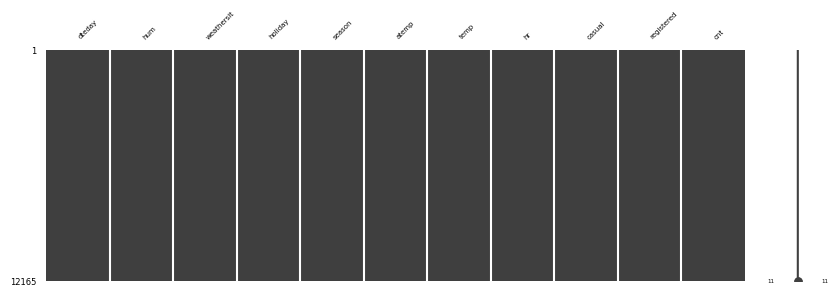

In [79]:
import missingno as msn
msn.matrix(bike,figsize=(10,3),fontsize=5)

In [80]:
# check duplicate
bike.duplicated().sum()

0

 ## **Outlier Handling**

In [81]:
num_columns = bike[['hum','temp','atemp','cnt']]

In [82]:
num_columns.describe().loc[['max','50%','min','mean']]

,hum,temp,atemp,cnt
max,1.000000,1.000000,1.000000,970.000000
50%,0.620000,0.500000,0.484800,142.000000
min,0.000000,0.020000,0.000000,1.000000
mean,0.625451,0.498185,0.476996,189.271023


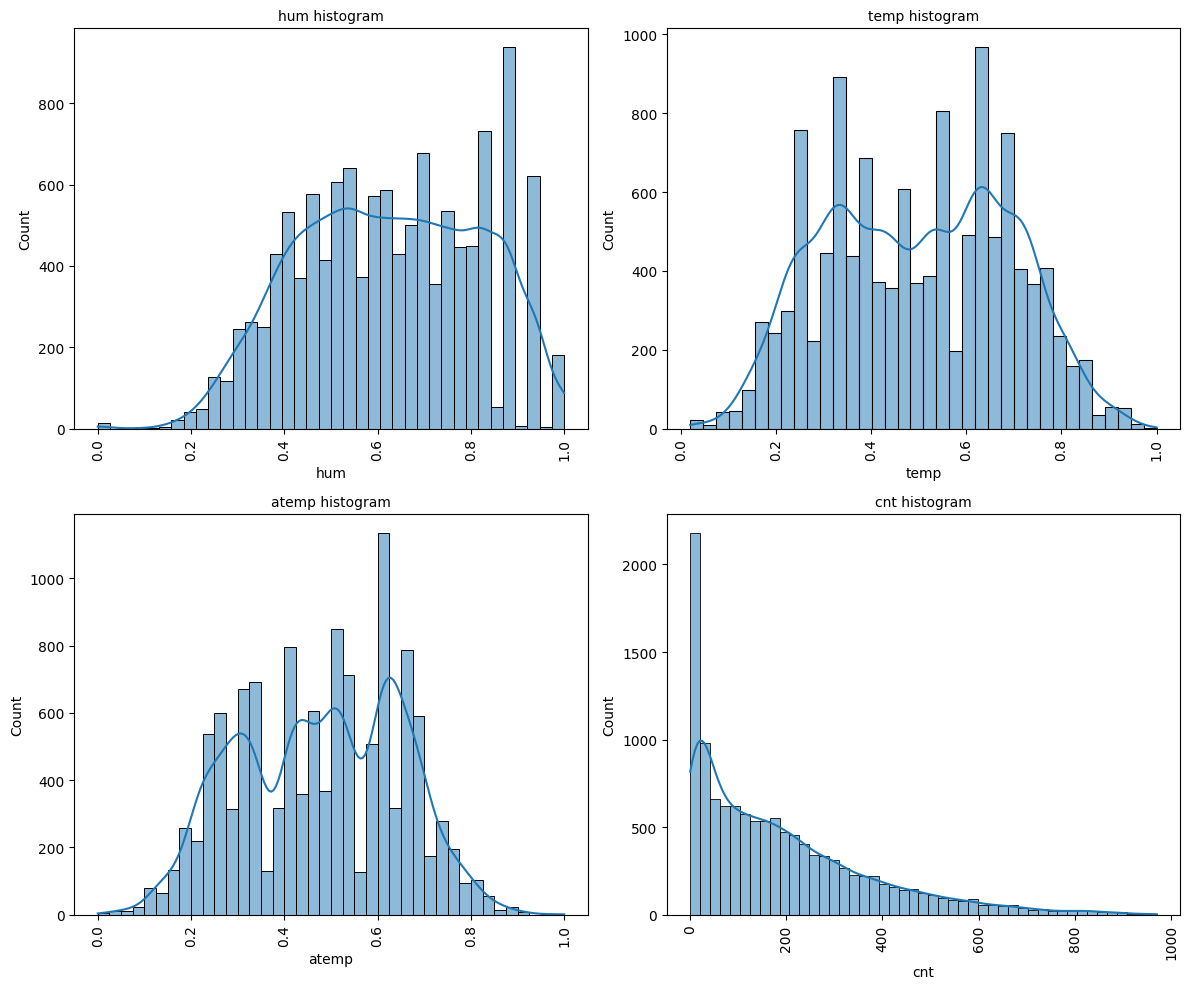

In [83]:
plt.figure(figsize=(12, 10))

for i, var in enumerate(num_columns.columns):
    plt.subplot(2, 2, i + 1)
    plt.title(f"{var} histogram", fontsize=10)
    sns.histplot(data=bike, x=var, kde=True)
    plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

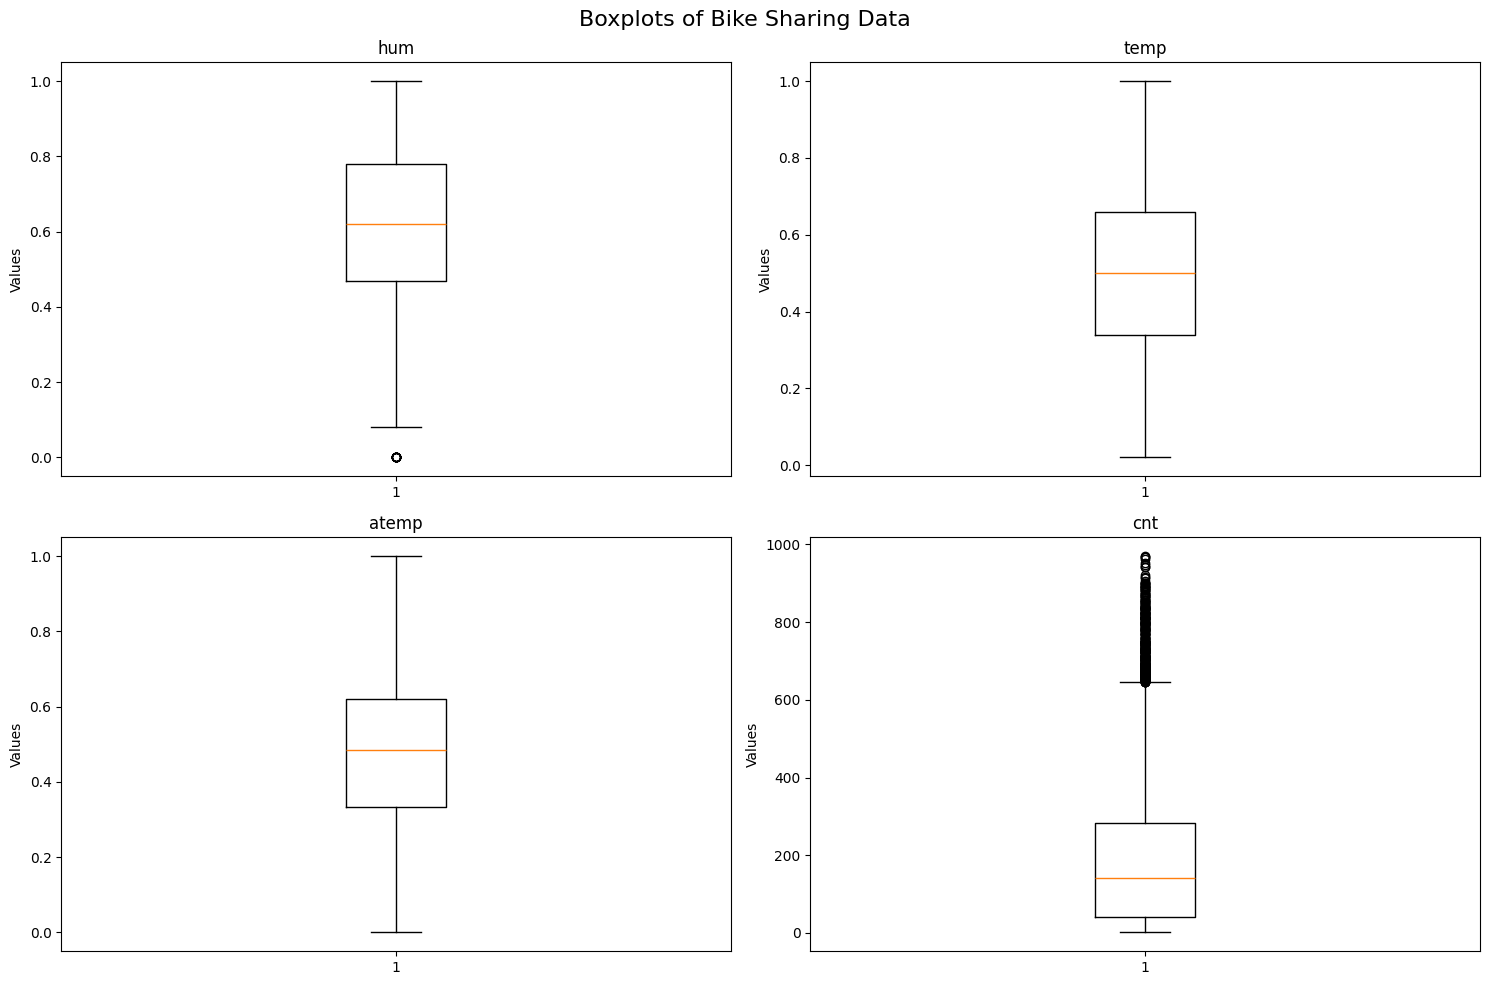

In [84]:
# Set up the plot
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('Boxplots of Bike Sharing Data', fontsize=16)

# Flatten the axes array for easier iteration
axes = axes.flatten()

# Create boxplots using a for loop
for i, column in enumerate(num_columns):
    axes[i].boxplot(bike[column])
    axes[i].set_title(column)
    axes[i].set_ylabel('Values')

# Adjust layout and display the plot
plt.tight_layout()
plt.show()

In [85]:
import scipy.stats as stats
def outlier_check(bike, var):
 """
 function to check outlier in variables
 """
 plt.figure(figsize=(16, 4))
 plt.subplot(1, 3, 1)
 plt.hist(data=bike, x=var)
 plt.title(f"Histogram of {var}")
 plt.subplot(1, 3, 2)
 stats.probplot(bike[var], dist="norm", plot=plt)
 plt.ylabel("RM Quantiles")
 plt.subplot(1, 3, 3)
 sns.boxplot(y = bike[var])
 plt.title(f"Boxplot of {var}")
 plt.show()

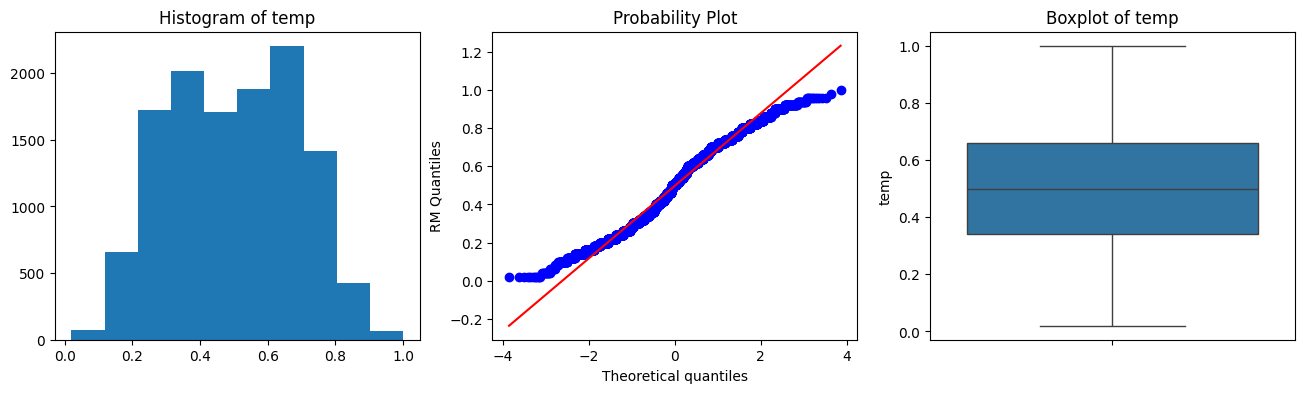

In [86]:
# visualize before transformation
outlier_check(bike, "temp")

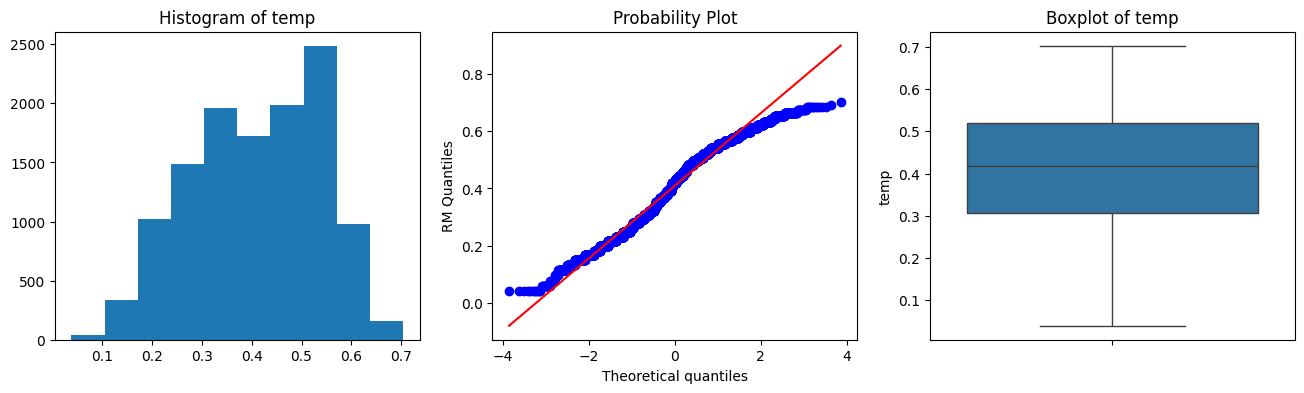

In [87]:
# try to transform value of size
 # this step is to normalize distribution of data
lt = LogCpTransformer()
lt.fit(bike[["temp"]])
# define transformer
# fit in data
samp = lt.transform(bike[["temp"]]) # transform data
# visulaize
outlier_check(samp, "temp")

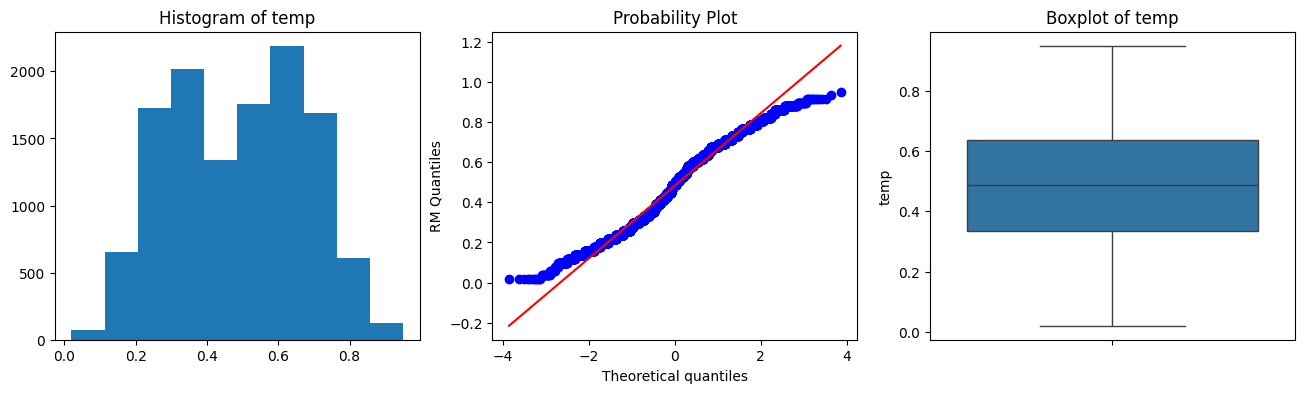

In [88]:
yjt = YeoJohnsonTransformer() # define transformer
yjt.fit(bike[["temp"]])
# fit in data
samp = yjt.transform(bike[["temp"]]) # transform data
# visualize
outlier_check(samp, "temp")

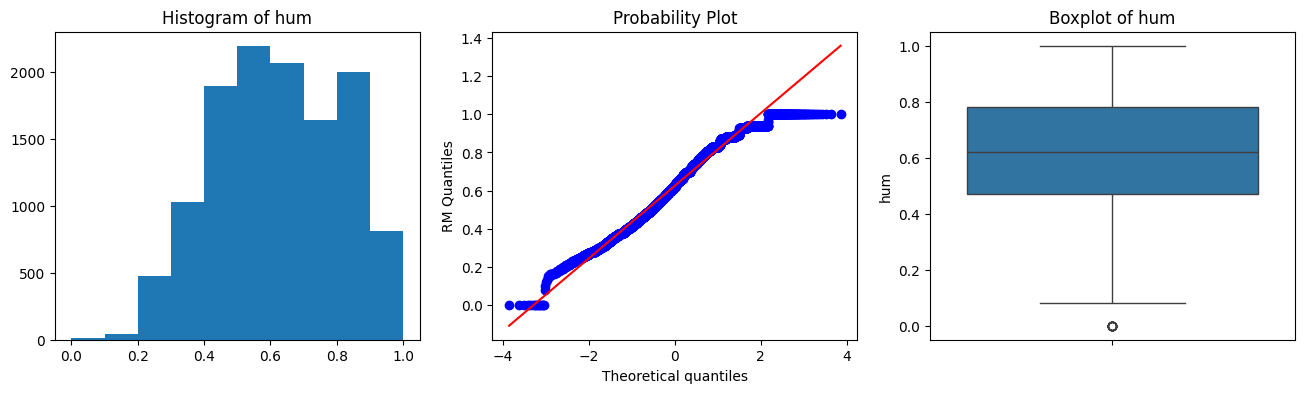

In [89]:
outlier_check(bike, "hum")

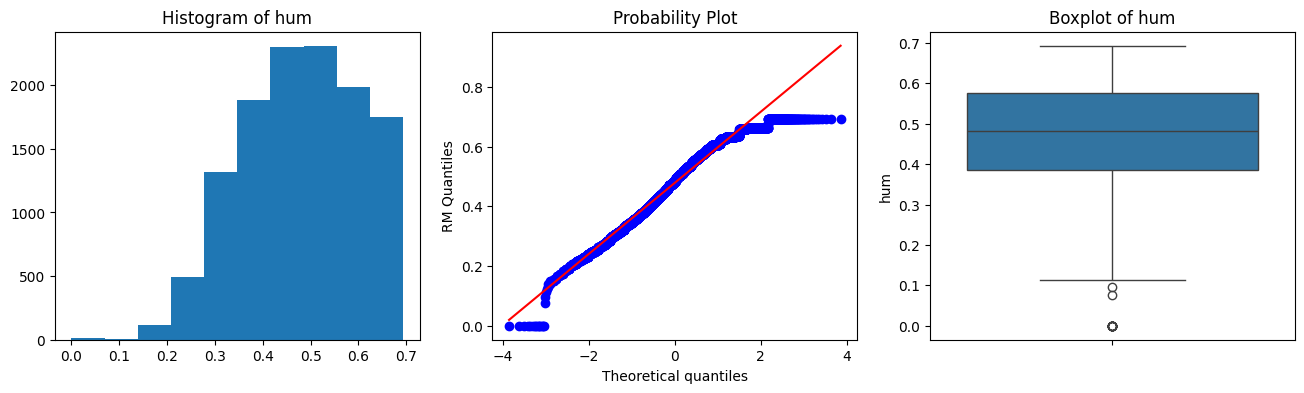

In [90]:
# try to transform value of size
 # this step is to normalize distribution of data
lt = LogCpTransformer()
lt.fit(bike[["hum"]])
# define transformer
# fit in data
samp = lt.transform(bike[["hum"]]) # transform data
# visulaize
outlier_check(samp, "hum")

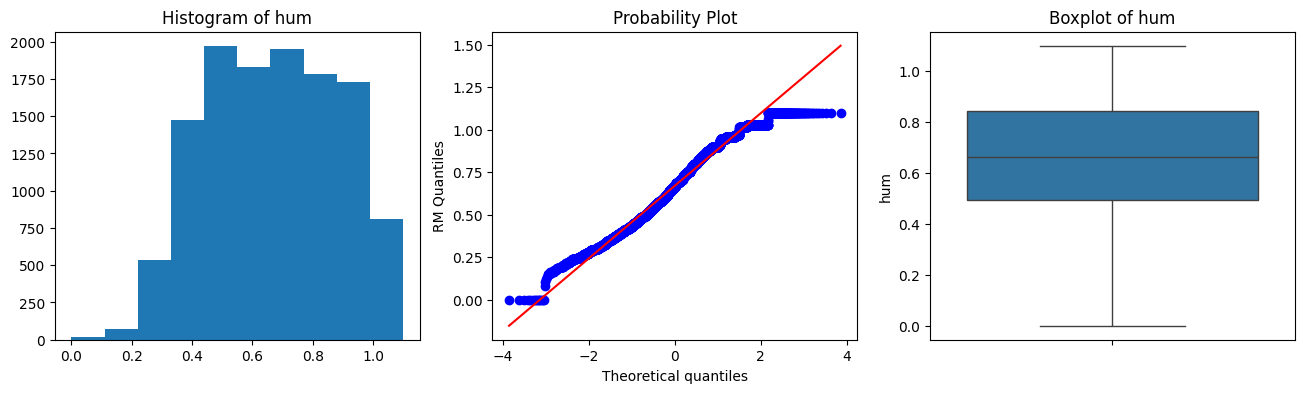

In [91]:
yjt = YeoJohnsonTransformer() # define transformer
yjt.fit(bike[["hum"]])
# fit in data
samp = yjt.transform(bike[["hum"]]) # transform data
# visualize
outlier_check(samp, "hum")

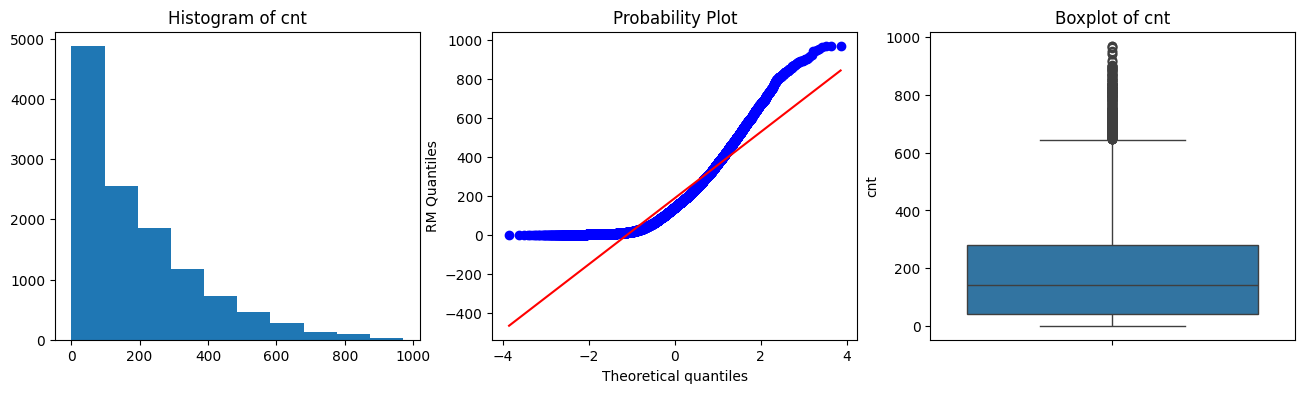

In [92]:
outlier_check(bike, "cnt")

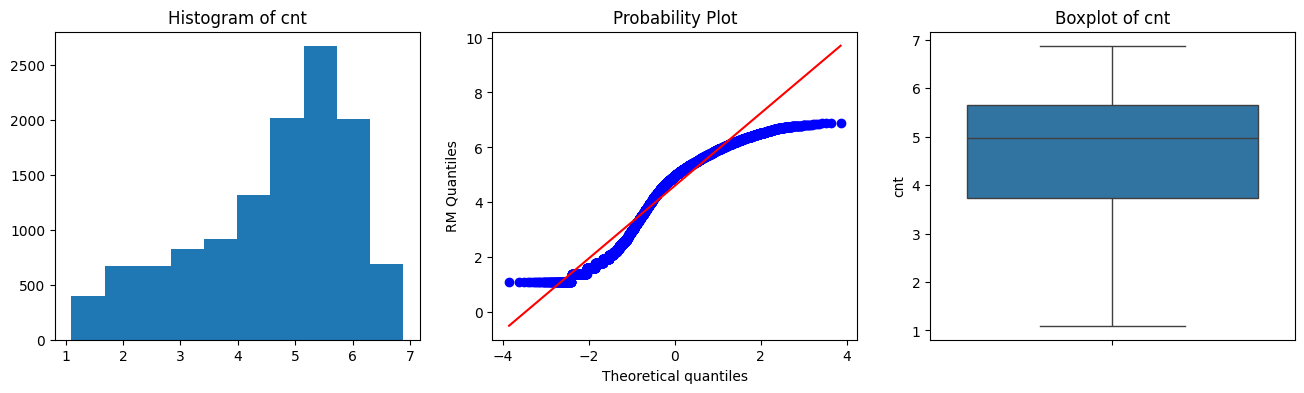

In [93]:
# try to transform value of size
 # this step is to normalize distribution of data
lt = LogCpTransformer()
lt.fit(bike[["cnt"]])
# define transformer
# fit in data
samp = lt.transform(bike[["cnt"]]) # transform data
# visulaize
outlier_check(samp, "cnt")

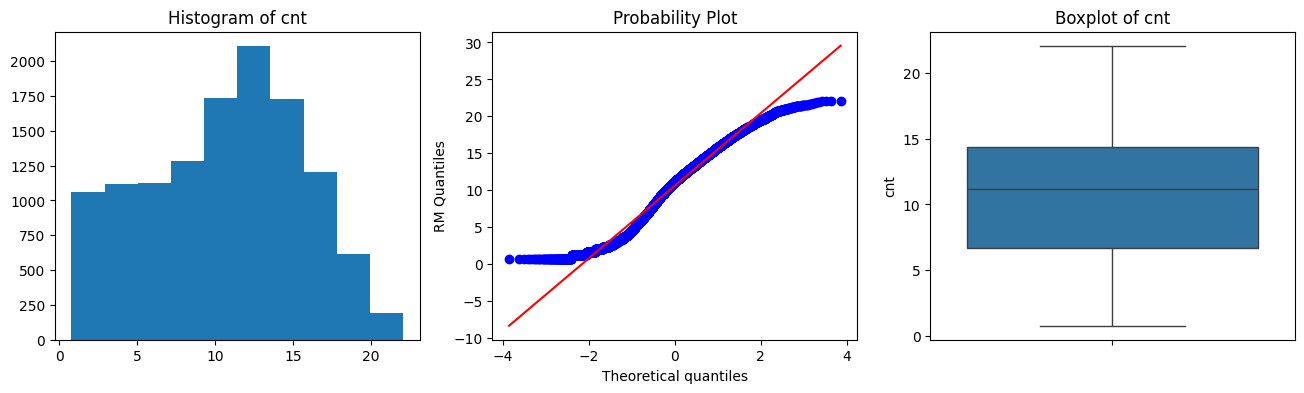

In [94]:
yjt = YeoJohnsonTransformer() # define transformer
yjt.fit(bike[["cnt"]])
# fit in data
samp = yjt.transform(bike[["cnt"]]) # transform data
# visualize
outlier_check(samp, "cnt")

In [95]:
# # Outliers for casual check
# outliers = bike[bike['cnt'] >= 614]

# # Count occurrences of each dteday
# dteday_counts = outliers['dteday'].value_counts()

# # Filter for dteday values that occur more than once
# repeated_dtedays = dteday_counts[dteday_counts > 1].index

# # Filter outliers for those dteday values
# outliers_with_repeated_dtedays = outliers[outliers['dteday'].isin(repeated_dtedays)]
# outliers_with_repeated_dtedays.sort_values(by='registered', ascending=False)

In [96]:
# # Outliers for humidity check
# outliers = bike[bike['hum'] <= 0.0500]
# outliers

In [97]:
# results = {}

# for col in num_columns:
#     q3 = bike[col].describe().loc['75%']
#     q1 = bike[col].describe().loc['25%']

#     iqr = q3 - q1

#     upper = q3 + 1.5 * iqr
#     lower = q1 - 1.5 * iqr

#     # Count outliers
#     upper_outliers = (bike[col] > upper).sum()
#     lower_outliers = (bike[col] < lower).sum()
#     total_outliers = upper_outliers + lower_outliers

#     # Calculate percentages
#     total_count = len(bike[col])
#     upper_percent = (upper_outliers / total_count) * 100
#     lower_percent = (lower_outliers / total_count) * 100
#     total_percent = (total_outliers / total_count) * 100

#     results[col] = {
#         'Upper fence': upper,
#         'Lower fence': lower,
#         'Upper outliers': upper_outliers,
#         'Upper outliers %': upper_percent,
#         'Lower outliers': lower_outliers,
#         'Lower outliers %': lower_percent,
#         'Total outliers': total_outliers,
#         'Total outliers %': total_percent
#     }

# show_outliers = pd.DataFrame(results).T.sort_values(by='Total outliers', ascending=False)
# show_outliers

In [98]:
# bike_new = bike[bike['hum'] >= 0.00500]
# print(bike_new.shape)

In [99]:
# bike_new = bike[bike['cnt'] <= 645.00000]
# print(bike_new.shape)

 ## **Feature Engineering**

In [100]:
bike['dteday'] = pd.to_datetime(bike['dteday'])
bike['day'] = bike['dteday'].dt.day_of_week
bike['month'] = bike['dteday'].dt.month

In [101]:
bike_new=bike[['hum','weathersit','holiday','season','temp','atemp','hr','cnt','day','month']]
bike_new.columns

Index(['hum', 'weathersit', 'holiday', 'season', 'temp', 'atemp', 'hr', 'cnt',
       'day', 'month'],
      dtype='object')

In [102]:
# # Define the time ranges
# bins = [-1, 5, 11, 17, 23]
# labels = ['Night', 'Morning', 'Day', 'Evening']

# # Replace the 'hr' column with the new time ranges
# bike_new['daytime'] = pd.cut(bike['hr'], bins=bins, labels=labels)

In [103]:
# Define a function to map months to quarters
def map_quarter(month):
    if month in [1, 2, 3]:
        return 1
    elif month in [4, 5, 6]:
        return 2
    elif month in [7, 8, 9]:
        return 3
    elif month in [10, 11, 12]:
        return 4
    else:
        return None  # Handle any unexpected values gracefully

# Apply the mapping function to create a new column 'quarter'
bike_new['quarter'] = bike_new['month'].apply(map_quarter)


In [104]:
bike_new['rush_hour'] = np.where(((bike_new['hr'] >= 7) & (bike_new['hr'] < 9)) | ((bike_new['hr'] >= 17) & (bike_new['hr'] < 19)), 1, 0)

In [105]:
bike_new['season'].replace({1: 'Winter', 2: 'Spring', 3: 'Summer', 4: 'Fall'}, inplace=True)
bike_new['weathersit'].replace({1: 'Clear', 2: 'Mist', 3: 'Light Rain/Snow', 4: 'Heavy Rain/Snow'}, inplace=True)
bike_new['holiday'].replace({1:'Yes', 0:'No'}, inplace=True)

In [106]:
bike_new['season']=bike_new['season'].astype('object')
bike_new['weathersit']=bike_new['weathersit'].astype('object')
bike_new['month']=bike_new['month'].astype('object')
bike_new['day']=bike_new['day'].astype('object')
# bike_new['daytime']=bike_new['daytime'].astype('object')
bike_new['holiday']=bike_new['holiday'].astype('object')
bike_new['quarter']=bike_new['quarter'].astype('object')
bike_new['rush_hour'] = bike_new['rush_hour'].astype('object')

In [107]:
bike_new.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12165 entries, 0 to 12164
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   hum         12165 non-null  float64
 1   weathersit  12165 non-null  object 
 2   holiday     12165 non-null  object 
 3   season      12165 non-null  object 
 4   temp        12165 non-null  float64
 5   atemp       12165 non-null  float64
 6   hr          12165 non-null  int64  
 7   cnt         12165 non-null  int64  
 8   day         12165 non-null  object 
 9   month       12165 non-null  object 
 10  quarter     12165 non-null  object 
 11  rush_hour   12165 non-null  object 
dtypes: float64(3), int64(2), object(7)
memory usage: 1.1+ MB


## **Preprocessing**

In [108]:
cat_columns = bike_new[['weathersit','season','holiday','day','month']]

In [109]:
pd.set_option('display.max_colwidth', None)

pd.DataFrame({
    'feature':cat_columns.columns.values,
    'negative':[True if cat_columns[i].dtype == int and (cat_columns[i] < 0).any() else False for i in cat_columns.columns],
    'n_unique':cat_columns.nunique().values,
    'sample_unique':[cat_columns[i].unique() for i in cat_columns.columns]
})

,feature,negative,n_unique,sample_unique
0,weathersit,False,4,"[Clear, Mist, Light Rain/Snow, Heavy Rain/Snow]"
1,season,False,4,"[Fall, Spring, Summer, Winter]"
2,holiday,False,2,"[No, Yes]"
3,day,False,7,"[4, 6, 2, 5, 1, 0, 3]"
4,month,False,12,"[12, 6, 3, 7, 10, 8, 1, 2, 5, 9, 4, 11]"


<Axes: title={'center': 'After Min-Max Scaling'}, xlabel='temp', ylabel='Density'>

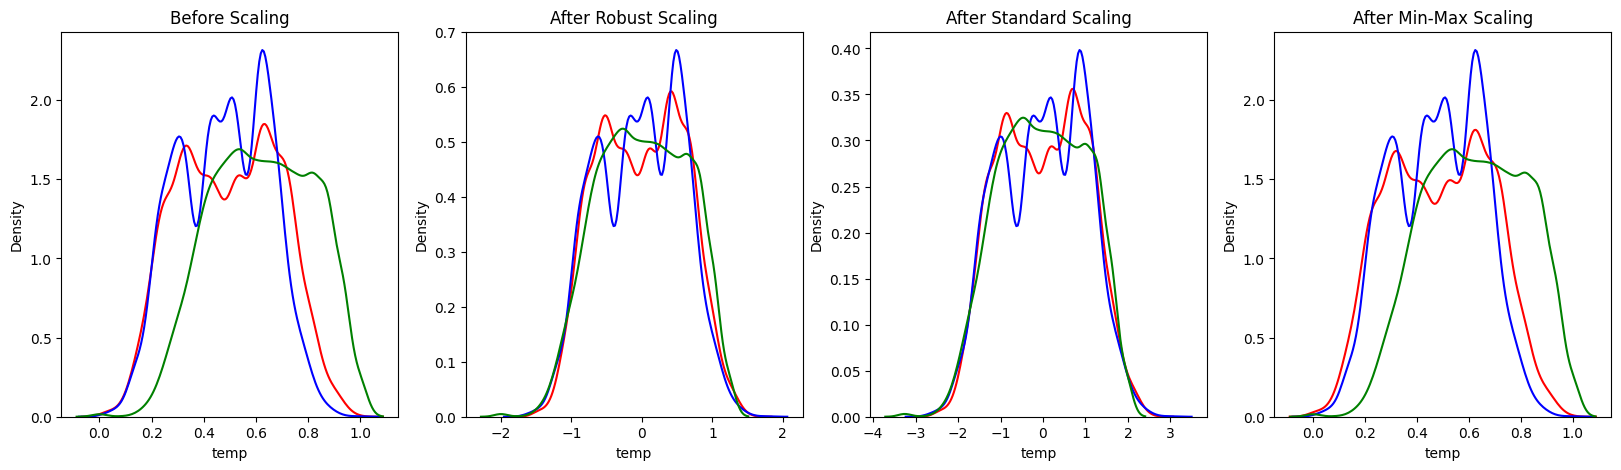

In [110]:
test = num_columns
scalerR = RobustScaler()
robust_df = scalerR.fit_transform(test)
robust_df = pd.DataFrame(robust_df, columns=test.columns)

scalerS = StandardScaler()
standard_df = scalerS.fit_transform(test)
standard_df = pd.DataFrame(standard_df, columns=test.columns)

scalerM = MinMaxScaler()
minmax_df = scalerM.fit_transform(test)
minmax_df = pd.DataFrame(minmax_df, columns=test.columns)

fig, (ax1, ax2, ax3, ax4) = plt.subplots(ncols = 4, figsize =(20, 5))
ax1.set_title('Before Scaling')

sns.kdeplot(test['temp'], ax = ax1, color ='r')
sns.kdeplot(test['atemp'], ax = ax1, color ='b')
sns.kdeplot(test['hum'], ax = ax1, color ='g')
ax2.set_title('After Robust Scaling')

sns.kdeplot(robust_df['temp'], ax = ax2, color ='red')
sns.kdeplot(robust_df['atemp'], ax = ax2, color ='blue')
sns.kdeplot(robust_df['hum'], ax = ax2, color ='green')

ax3.set_title('After Standard Scaling')

sns.kdeplot(standard_df['temp'], ax = ax3, color ='r')
sns.kdeplot(standard_df['atemp'], ax = ax3, color ='b')
sns.kdeplot(standard_df['hum'], ax = ax3, color ='g')

ax4.set_title('After Min-Max Scaling')

sns.kdeplot(minmax_df['temp'], ax = ax4, color ='r')
sns.kdeplot(minmax_df['atemp'], ax = ax4, color ='b')
sns.kdeplot(minmax_df['hum'], ax = ax4, color ='g')

 ***
 # **Feature Selection**
 ***

## **Numerical Features Selection**

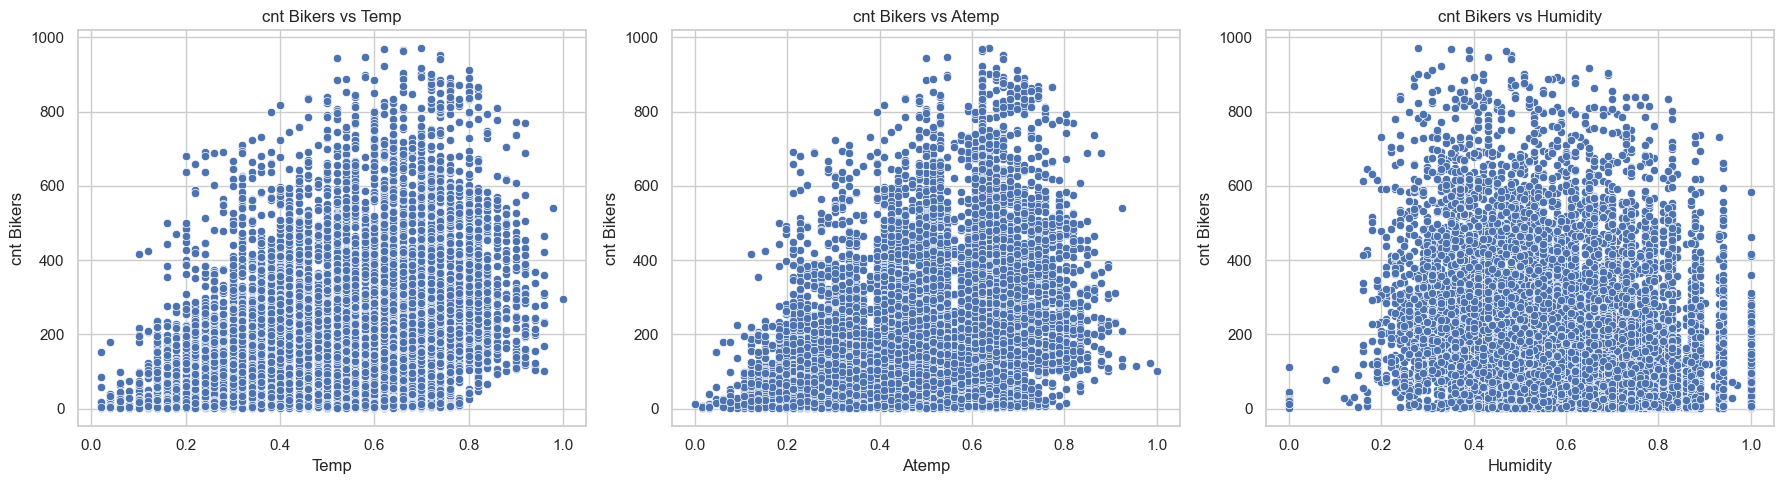

In [111]:
# Set up the plotting environment
sns.set(style="whitegrid")

# Create scatter plots for cnt bikers against temp, atemp, and hum
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Scatter plot for temp vs cnt
sns.scatterplot(ax=axes[0], x='temp', y='cnt', data=bike_new)
axes[0].set_title('cnt Bikers vs Temp')
axes[0].set_xlabel('Temp')
axes[0].set_ylabel('cnt Bikers')

# Scatter plot for atemp vs cnt
sns.scatterplot(ax=axes[1], x='atemp', y='cnt', data=bike_new)
axes[1].set_title('cnt Bikers vs Atemp')
axes[1].set_xlabel('Atemp')
axes[1].set_ylabel('cnt Bikers')

# Scatter plot for hum vs cnt
sns.scatterplot(ax=axes[2], x='hum', y='cnt', data=bike_new)
axes[2].set_title('cnt Bikers vs Humidity')
axes[2].set_xlabel('Humidity')
axes[2].set_ylabel('cnt Bikers')

# Show the plots
plt.tight_layout()
plt.show()

In [112]:
sm_lm = sm.OLS(bike_new['cnt'], sm.add_constant(bike_new[['temp']]))
result = sm_lm.fit()
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.161
Model:                            OLS   Adj. R-squared:                  0.161
Method:                 Least Squares   F-statistic:                     2333.
Date:                Sun, 14 Jul 2024   Prob (F-statistic):               0.00
Time:                        00:14:38   Log-Likelihood:                -79448.
No. Observations:               12165   AIC:                         1.589e+05
Df Residuals:                   12163   BIC:                         1.589e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.1228      4.176      0.269      0.7

In [113]:
sm_lm = sm.OLS(bike_new['cnt'], sm.add_constant(bike_new[['atemp']]))
result = sm_lm.fit()
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.159
Model:                            OLS   Adj. R-squared:                  0.159
Method:                 Least Squares   F-statistic:                     2300.
Date:                Sun, 14 Jul 2024   Prob (F-statistic):               0.00
Time:                        00:14:38   Log-Likelihood:                -79462.
No. Observations:               12165   AIC:                         1.589e+05
Df Residuals:                   12163   BIC:                         1.589e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -11.3047      4.446     -2.543      0.0

In [114]:
sm_lm = sm.OLS(bike_new['cnt'], sm.add_constant(bike_new[['hum']]))
result = sm_lm.fit()
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.102
Model:                            OLS   Adj. R-squared:                  0.102
Method:                 Least Squares   F-statistic:                     1380.
Date:                Sun, 14 Jul 2024   Prob (F-statistic):          3.04e-286
Time:                        00:14:38   Log-Likelihood:                -79862.
No. Observations:               12165   AIC:                         1.597e+05
Df Residuals:                   12163   BIC:                         1.597e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        377.6252      5.304     71.198      0.0

In [115]:
sm_lm = sm.OLS(bike_new['cnt'], sm.add_constant(bike_new[['temp','atemp']]))
result = sm_lm.fit()
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.161
Model:                            OLS   Adj. R-squared:                  0.161
Method:                 Least Squares   F-statistic:                     1169.
Date:                Sun, 14 Jul 2024   Prob (F-statistic):               0.00
Time:                        00:14:38   Log-Likelihood:                -79446.
No. Observations:               12165   AIC:                         1.589e+05
Df Residuals:                   12162   BIC:                         1.589e+05
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -3.1441      4.670     -0.673      0.5

In [116]:
sm_lm = sm.OLS(bike_new['cnt'], sm.add_constant(bike_new[['temp','hum']]))
result = sm_lm.fit()
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.246
Model:                            OLS   Adj. R-squared:                  0.246
Method:                 Least Squares   F-statistic:                     1988.
Date:                Sun, 14 Jul 2024   Prob (F-statistic):               0.00
Time:                        00:14:38   Log-Likelihood:                -78795.
No. Observations:               12165   AIC:                         1.576e+05
Df Residuals:                   12162   BIC:                         1.576e+05
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        183.4626      6.307     29.088      0.0

In [117]:
sm_lm = sm.OLS(bike_new['cnt'], sm.add_constant(bike_new[['atemp','hum']]))
result = sm_lm.fit()
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.248
Model:                            OLS   Adj. R-squared:                  0.248
Method:                 Least Squares   F-statistic:                     2010.
Date:                Sun, 14 Jul 2024   Prob (F-statistic):               0.00
Time:                        00:14:38   Log-Likelihood:                -78779.
No. Observations:               12165   AIC:                         1.576e+05
Df Residuals:                   12162   BIC:                         1.576e+05
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        173.1373      6.417     26.979      0.0

In [118]:
sm_lm = sm.OLS(bike_new['cnt'], sm.add_constant(bike_new[['temp','atemp','hum']]))
result = sm_lm.fit()

In [119]:
print(result.summary())

                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.249
Model:                            OLS   Adj. R-squared:                  0.248
Method:                 Least Squares   F-statistic:                     1341.
Date:                Sun, 14 Jul 2024   Prob (F-statistic):               0.00
Time:                        00:14:39   Log-Likelihood:                -78777.
No. Observations:               12165   AIC:                         1.576e+05
Df Residuals:                   12161   BIC:                         1.576e+05
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        174.5651      6.471     26.978      0.0

In [120]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
def calc_vif(X):

    # Calculating VIF
    vif = pd.DataFrame()
    vif["variables"] = X.columns
    vif["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

    return(vif)

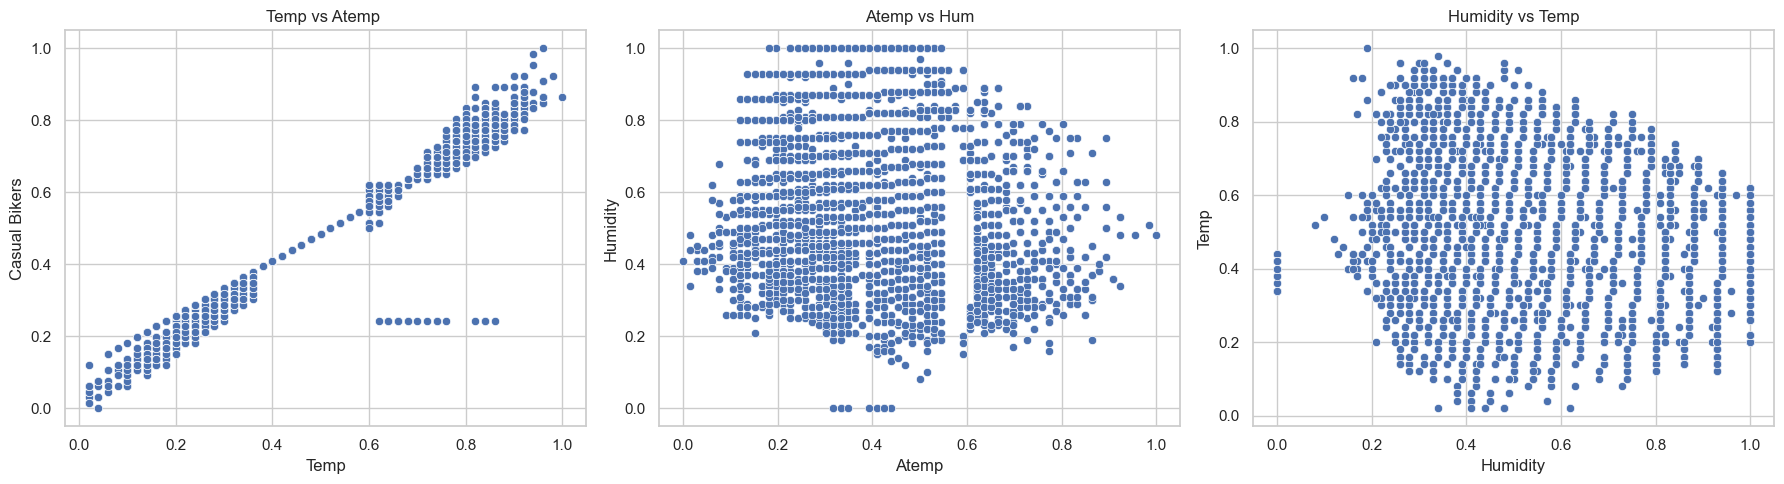

In [121]:
# Set up the plotting environment
sns.set(style="whitegrid")

# Create scatter plots for casual bikers against temp, atemp, and hum
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Scatter plot for temp vs casual
sns.scatterplot(ax=axes[0], x='temp', y='atemp', data=bike_new)
axes[0].set_title('Temp vs Atemp ')
axes[0].set_xlabel('Temp')
axes[0].set_ylabel('Casual Bikers')

# Scatter plot for atemp vs casual
sns.scatterplot(ax=axes[1], x='atemp', y='hum', data=bike_new)
axes[1].set_title('Atemp vs Hum')
axes[1].set_xlabel('Atemp')
axes[1].set_ylabel('Humidity')

# Scatter plot for hum vs casual
sns.scatterplot(ax=axes[2], x='hum', y='temp', data=bike_new)
axes[2].set_title('Humidity vs Temp')
axes[2].set_xlabel('Humidity')
axes[2].set_ylabel('Temp')

# Show the plots
plt.tight_layout()
plt.show()

In [122]:
calc_vif(bike_new[['temp','atemp']])

,variables,VIF
0,temp,276.900478
1,atemp,276.900478


In [123]:
calc_vif(bike_new[['temp','hum']])

,variables,VIF
0,temp,4.590726
1,hum,4.590726


In [124]:
calc_vif(bike_new[['atemp','hum']])

,variables,VIF
0,atemp,4.989441
1,hum,4.989441


In [125]:
calc_vif(bike_new[['temp','atemp','hum']])

,variables,VIF
0,temp,305.037325
1,atemp,331.530523
2,hum,5.496436


<center>

| F | p-value | R-squared | Adj. R-squared | X1 | X2 | X3 | VIF |
|---------|-------------------------|------------------------|--------------|--------------|--------------|--------------|--------------|
| 4320    | 0.00               | 0.277              | 0.276    | X    |     |     | 1.00    |
| 4127    | 0.00               | 0.267               | 0.267    |     | X    |     |1.00   |
| 0.267  | 0.00                | 0.128               | 0.128    |     |     | X     | 1.00    |
| 2162    | 0.00                | 0.277               | 0.277    | X    | X    |     | 270.27   |
| 3691    | 0.00                | 0.395               | 0.395   | X    |     | X    | 4.77    |
| 3644    | 0.00                | 0.392               | 0.392  |     | X    | X    | 5.19    |
| 2465    | 0.00                | 0.396               | 0.395 |  X   |  X   |  X   | below   |
|     |     |     |     | 296.13    | 322.4    | 5.69    |     |
<center>

***
# **Model Training**
***

## **Data Splitting**

In [126]:
X = bike_new.drop(columns=['cnt','atemp','month'])
y = bike_new['cnt']

In [127]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [128]:
y_train = np.log(y_train)
y_test = np.log(y_test)

In [141]:
# from sklearn.preprocessing import OneHotEncoder, RobustScaler
# from sklearn.compose import ColumnTransformer

# standard = SklearnTransformerWrapper(StandardScaler(), ['temp','hum'])

# transformer = ColumnTransformer([
#     ('onehot', OneHotEncoder(drop='first'), ['weathersit', 'holiday', 'season','quarter','day','rush_hour']),
# ], remainder='passthrough')

In [153]:
standard_vars = [
    'temp',
    'hum'
]

one_hot_vars = [
'weathersit'
, 'holiday'
, 'season'
, 'quarter'
, 'day'
, 'rush_hour'
]

In [130]:
# X_train.reset_index(drop=True, inplace=True)
# X_test.reset_index(drop=True, inplace=True)
# y_train.reset_index(drop=True, inplace=True)
# y_test.reset_index(drop=True, inplace=True)

In [131]:
# X_train_preprocessed = transformer.fit_transform(X_train)
# X_test_preprocessed = transformer.transform(X_test)

In [132]:
# transformer.get_feature_names_out()

In [133]:
# features = list(transformer.get_feature_names_out())

# list_features = []

# for feature in features:
#     list_features.append('_'.join(feature.split('_')[2:]))

# list_features

## **Benchmark Model**

In [149]:
rf =  RandomForestRegressor(n_estimators=150, random_state=42)
gbc = GradientBoostingRegressor(n_estimators=150, random_state=42)
ada = AdaBoostRegressor(n_estimators=150, random_state=42)
xgb = XGBRegressor(n_estimators=150, random_state=42)

In [135]:
# permodelan dilakukan dalam skala logaritmik, namun kemudian di-inverse kembali untuk interpretasi
# fungsi logaritmik digunakan untuk melinierkan target, memungkinkan prediksi yang lebih baik
# log_gbc = TransformedTargetRegressor(gbc, func=np.log, inverse_func=np.exp)
# log_ada = TransformedTargetRegressor(ada, func=np.log, inverse_func=np.exp)
# log_rf = TransformedTargetRegressor(rf, func=np.log, inverse_func=np.exp)
# log_xgb = TransformedTargetRegressor(xgb, func=np.log, inverse_func=np.exp)

In [160]:
one_hot_vars = ['cat_feature']  # replace with your actual categorical feature names
standard_vars = ['num_feature']  # replace with your actual numerical feature names

# Define transformers for categorical and numerical features
categorical_transformer = OneHotEncoder(drop='first', sparse_output=False)
numerical_transformer = StandardScaler()

# Combine transformers into a ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, standard_vars),
        ('cat', categorical_transformer, one_hot_vars)
    ])

# Define the complete pipeline
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    # Add the model step here, e.g., ('model', model)
])

estimator.fit(X_train)

X_train_preprocess = estimator.transform(X_train)
X_test_preprocess = estimator.transform(X_test)

TypeError: This transformer does not support sparse matrices.

In [72]:
# # Import necessary libraries
# from sklearn.compose import TransformedTargetRegressor
# from sklearn.model_selection import KFold, cross_val_score
# from sklearn.pipeline import Pipeline
# import numpy as np

# # Assuming log_ada, log_gbc, log_rf, log_xgb, transformer, X_train_preprocessed, and y_train are already defined

# # List of models
# models = [ada,gbc,rf,xgb]

# score_rmse = []
# mean_rmse = []
# std_rmse = []

# score_mae = []
# mean_mae = []
# std_mae = []

# score_mape = []
# mean_mape = []
# std_mape = []

# # Searching for the best algorithm based on each metric
# for i in models:
#     # 5-fold cross-validation
#     crossval = KFold(n_splits=5, shuffle=True, random_state=42)

#     estimator = Pipeline([
#         ('scaler', standard),
#         ('model', i)
#     ])

#     # RMSE
#     model_cv_rmse = cross_val_score(
#         estimator,
#         X_train_preprocessed,
#         y_train,
#         cv=crossval,
#         scoring='neg_root_mean_squared_error',
#         error_score='raise'
#     )

#     score_rmse.append(np.abs(model_cv_rmse))
#     mean_rmse.append(np.abs(model_cv_rmse).mean())
#     std_rmse.append(np.abs(model_cv_rmse).std())

#     # MAE
#     model_cv_mae = cross_val_score(
#         estimator,
#         X_train_preprocessed,
#         y_train,
#         cv=crossval,
#         scoring='neg_mean_absolute_error',
#         error_score='raise'
#     )

#     score_mae.append(np.abs(model_cv_mae))
#     mean_mae.append(np.abs(model_cv_mae).mean())
#     std_mae.append(np.abs(model_cv_mae).std())

#     # MAPE
#     model_cv_mape = cross_val_score(
#         estimator,
#         X_train_preprocessed,
#         y_train,
#         cv=crossval,
#         scoring='neg_mean_absolute_percentage_error',
#         error_score='raise'
#     )

#     score_mape.append(np.abs(model_cv_mape))
#     mean_mape.append(np.abs(model_cv_mape).mean())
#     std_mape.append(np.abs(model_cv_mape).std())


TypeError: This transformer does not support sparse matrices.

In [72]:
# Evaluasi hasil dari 5 kandidat algoritma yang digunakan
benchmark_train = pd.DataFrame({
    'Model': ['AdaBoost Regressor','GradientBoost Regressor', 'RandomForest Regressor', 'XGBoost Regressor'],
    'Train RMSE': mean_rmse,
    'Std RMSE': std_rmse,
    'Train MAE': mean_mae,
    'Std MAE': std_mae,
    'Train MAPE': mean_mape,
    'Std MAPE': std_mape
}).sort_values('Train RMSE', ascending=True)
benchmark_train

,Model,Train RMSE,Std RMSE,Train MAE,Std MAE,Train MAPE,Std MAPE
3,XGBoost Regressor,60.832580,1.242169,40.017262,0.947268,0.347333,0.008633
2,RandomForest Regressor,65.144047,2.086503,42.526797,1.308874,0.379142,0.014163
1,GradientBoost Regressor,77.228187,0.954955,49.823990,0.600008,0.438489,0.017262
0,AdaBoost Regressor,120.285491,4.242942,77.332301,1.972521,0.616235,0.035818


In [73]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
import numpy as np

models = [log_ada, log_gbc, log_rf, log_xgb]
# List to store test scores
test_score_rmse = []
test_score_mae = []
test_score_mape = []

# Evaluate each model on the test set
for i in models:
    estimator = Pipeline([
        ('preprocessing', transformer),
        ('model', i)
    ])

    # Fit the model
    estimator.fit(X_train, y_train)

    # Predict on the test set
    y_pred = estimator.predict(X_test)

    # Calculate RMSE
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    test_score_rmse.append(rmse)

    # Calculate MAE
    mae = mean_absolute_error(y_test, y_pred)
    test_score_mae.append(mae)

    # Calculate MAPE
    mape = mean_absolute_percentage_error(y_test, y_pred)
    test_score_mape.append(mape)


coba global outlier numerikal


mape = distribusi y_train sama y_pred

predksi gboleh ada yg mines

In [74]:
results = {
    'Model': ['AdaBoost Regressor','GradientBoost Regressor', 'RandomForest Regressor', 'XGBoost Regressor'],
    'Test RMSE': test_score_rmse,
    'Test MAE': test_score_mae,
    'Test MAPE': test_score_mape
}

# Creating DataFrame
results_test = pd.DataFrame(results)
results_test.sort_values('Test RMSE', ascending=True)


,Model,Test RMSE,Test MAE,Test MAPE
3,XGBoost Regressor,60.206210,39.424705,0.351022
2,RandomForest Regressor,62.943535,41.238769,0.371961
1,GradientBoost Regressor,77.130647,49.907965,0.432952
0,AdaBoost Regressor,115.480260,73.203453,0.612813


In [75]:
# combine and compare
benchmark_model = results_test.set_index('Model').join(benchmark_train.set_index('Model'))
benchmark_model.drop(['Train RMSE','Std RMSE','Train MAE','Std MAE','Std MAPE','Test RMSE','Test MAE'],axis=1,inplace=True)
benchmark_model['diff'] = benchmark_model['Train MAPE'] - benchmark_model['Test MAPE']
benchmark_model['diff'] = benchmark_model['diff'].agg('abs')
benchmark_model.sort_values(by='Test MAPE',ascending=True)

,Test MAPE,Train MAPE,diff
Model,,,
XGBoost Regressor,0.351022,0.347333,0.003689
RandomForest Regressor,0.371961,0.379142,0.007181
GradientBoost Regressor,0.432952,0.438489,0.005537
AdaBoost Regressor,0.612813,0.616235,0.003423


In [76]:
# kedalaman pohon
max_depth = list(np.arange(5, 15)) #semakin tinggi nilainya maka semakin kompleks dan meningkatkan kemungkinan overfitting

# learning rate
learning_rate = list(np.arange(1, 51)/100) #semakin rendah nilainya maka dapat meningkatkan peluang mencapai nilai optimum yang lebih baik namun dengan waktu komputasi yang lebih lambat

# jumlah pohon
n_estimators = list(np.arange(100, 251)) #ekuivalen dengan jumlah round dari boosting


In [77]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, RandomizedSearchCV
from xgboost import XGBRegressor

# Define the transformer and the base regressor
xgb = XGBRegressor(random_state=42)

# Define the pipeline
pipe_model = Pipeline([
    ('preprocess', transformer),
    ('model', TransformedTargetRegressor(regressor=xgb, func=np.log, inverse_func=np.exp))
])

# Define the cross-validation strategy
crossval = KFold(n_splits=5, shuffle=True, random_state=42)

# Define the hyperparameter space
hyperparam_space_xgb = {
    'model__regressor__n_estimators': [100,150, 200,250, 300],
    'model__regressor__max_depth': [3, 5, 7],
    'model__regressor__learning_rate': [0.01, 0.05, 0.1],
    'model__regressor__subsample': [0.8, 0.9, 1.0],
    'model__regressor__colsample_bytree': [0.8, 0.9, 1.0]
}

# Initialize the RandomizedSearchCV
random_search_xgb = RandomizedSearchCV(
    estimator=pipe_model,
    param_distributions=hyperparam_space_xgb,
    cv=crossval,
    scoring='neg_mean_absolute_percentage_error',
    n_iter=100,
    n_jobs=-1,
    random_state=42
)

# Fit the model
random_search_xgb.fit(X_train, y_train)

# Best parameters and best score
print("Best parameters found: ", random_search_xgb.best_params_)
print("Best MAPE: ", -random_search_xgb.best_score_)


Best parameters found:  {'model__regressor__subsample': 0.9, 'model__regressor__n_estimators': 300, 'model__regressor__max_depth': 5, 'model__regressor__learning_rate': 0.1, 'model__regressor__colsample_bytree': 0.8}
Best MAPE:  0.34089067285012975


In [79]:
# Model XGBoost
model = {'XGB': XGBRegressor(random_state=42)}

# Define model terhadap estimator terbaik
xgb_tuning = random_search_xgb.best_estimator_

# Fitting model
xgb_tuning.fit(X_train, y_train)

# Predict test set
y_pred_xgb_tuning = xgb_tuning.predict(X_test)

# Simpan nilai metrics RMSE, MAE & MAPE setelah tuning
rmse_xgb_tuning = np.sqrt(mean_squared_error(y_test, y_pred_xgb_tuning))
mae_xgb_tuning = mean_absolute_error(y_test, y_pred_xgb_tuning)
mape_xgb_tuning = mean_absolute_percentage_error(y_test, y_pred_xgb_tuning)

score_after_tuning = pd.DataFrame({'MAPE': mape_xgb_tuning}, index=model.keys())
score_after_tuning

,MAPE
XGB,0.34738


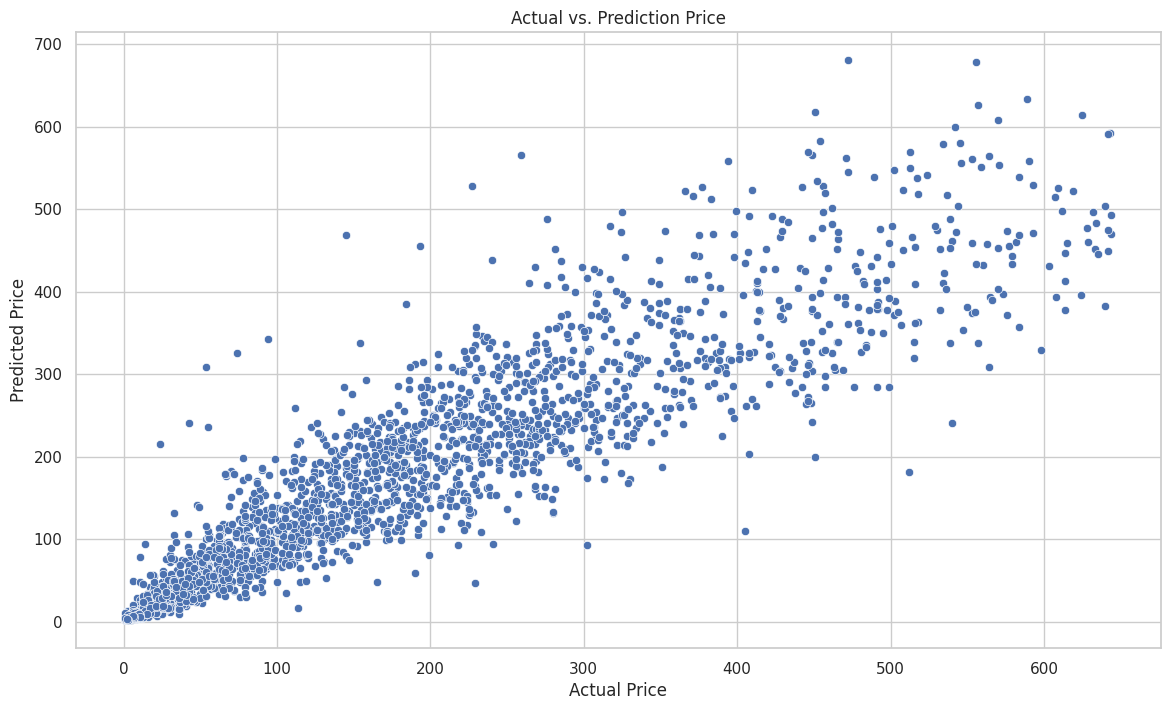

In [80]:
plt.figure(figsize=(14, 8))
plot = sns.scatterplot(x=y_test, y=y_pred_xgb_tuning).set(title='Actual vs. Prediction Price',
                                               xlabel='Actual Price',
                                               ylabel='Predicted Price');

In [82]:
features = list(transformer.get_feature_names_out())

list_features = []

for feature in features:
    list_features.append('_'.join(feature.split('_')[2:]))

list_features

['weathersit_Heavy Rain/Snow',
 'weathersit_Light Rain/Snow',
 'weathersit_Mist',
 'holiday_Yes',
 'season_Spring',
 'season_Summer',
 'season_Winter',
 'quarter_2',
 'quarter_3',
 'quarter_4',
 'day_1',
 'day_2',
 'day_3',
 'day_4',
 'day_5',
 'day_6',
 'rush_hour_1',
 'hum',
 'temp',
 'hr']

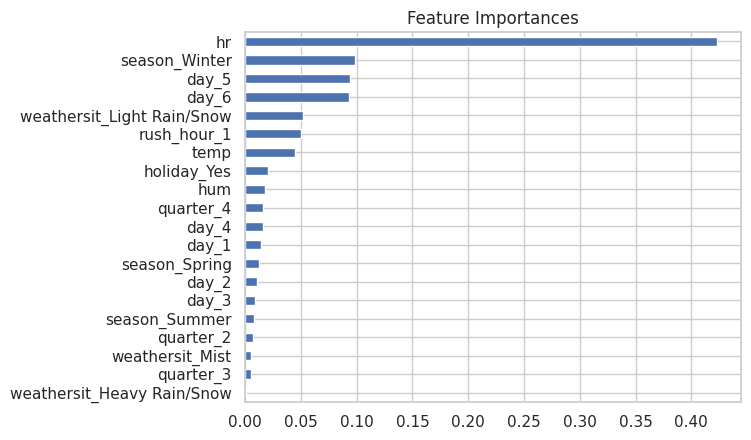

In [84]:
# Plot feature importances
feature_imp = pd.Series(xgb_tuning['model'].regressor_.feature_importances_, list_features).sort_values(ascending = True)
feature_imp.plot(kind='barh', title='Feature Importances');